# Week 8 Take Home

This week has two parts:

| Part | Lessons | Take-home work |
|------|---------|----------------|
| **A. Grouping & Aggregating Data** | `1-Grouping & Aggregating Data/` (notebooks 1–4) | Project 4 below + the notebook task solutions |
| **B. Data Visualization** | `2-Data Visualization (Seaborn & Matplotlib)/` (videos + scripts) | Re-create the plots from the videos using the Part A milk data: a histogram, a KDE plot, a box/violin plot, a regression plot and a heatmap. Add them at the end of this notebook. |

Part A data comes from the cohort database (schema `week09`). See `Data Access (SQL).md`.

---
# Part A: Grouping & Aggregating Data

## Project 4: Exploring the UK's milk imports and exports

A country's economy depends, sometimes heavily, on its exports and imports. The United Nations Comtrade database provides data on global trade. It will be used to analyse the UK's imports and exports of milk and cream in 2015:

- How much does the UK export and import and is the balance positive (more exports than imports)?
- Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?
- Which are the regular customers, i.e. which countries buy milk from the UK every month?
- Which countries does the UK both import from and export to?

In [ ]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

from pandas import *
%matplotlib inline

## Getting and preparing the data

The data is obtained from the [United Nations Comtrade](http://comtrade.un.org/data/) website, by selecting the following configuration:

- Type of Product: goods
- Frequency: monthly
- Periods: January to May of 2015
- Reporter: United Kingdom
- Partners: all
- Flows: imports and exports
- HS (as reported) commodity codes: 0401 (Milk and cream, neither concentrated nor sweetened) and 0402 (Milk and cream, concentrated or sweetened)

Clicking on 'Preview' results in a message that the data exceeds 500 rows. Data was downloaded using the *Download CSV* button and the download file renamed appropriately.

In [ ]:
LOCATION = 'comtrade_milk_uk_jan_jul_15.csv'

The data can also be downloaded directly from Comtrade using the "View API Call" URL, modified in two ways:

- `max=500` is increased to `max=5000` to make sure all data is loaded,
- `&fmt=csv` is added at the end to obtain the data in CSV format.

In [ ]:
# LOCATION = 'http://comtrade.un.org/api/get?max=5000&type=C&freq=M&px=HS&ps=201505%2C201504%2C201503%2C201502%2C201501&r=826&p=all&rg=1%2C2&cc=0401%2C0402&fmt=csv'

On reading in the data, the commodity code has to be read as a string, to not lose the leading zero.

In [ ]:
# Load Data from cohort database (schema week09). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

milk = run_query("SELECT * FROM week09.comtrade_milk_uk_jan_jul_15")
milk.tail(2)


,Classification,Year,Period,Period Desc.,Aggregate Level,Is Leaf Code,Trade Flow Code,Trade Flow,Reporter Code,Reporter,...,Qty,Alt Qty Unit Code,Alt Qty Unit,Alt Qty,Netweight (kg),Gross weight (kg),Trade Value (US$),CIF Trade Value (US$),FOB Trade Value (US$),Flag
635,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,2213,None,37883,None,None,0
636,HS,2015,201505,May 2015,4,0,2,Exports,826,United Kingdom,...,None,None,None,None,1588,None,5676,None,None,0


The data only covers the first five months of 2015. Most columns are irrelevant for this analysis, or contain always the same value, like the year and reporter columns. The commodity code is transformed into a short but descriptive text and only the relevant columns are selected.

In [ ]:
def milkType(code):
    if code == '0401': # neither concentrated nor sweetened
        return 'unprocessed'
    if code == '0402': # concentrated or sweetened
        return 'processed'
    return 'unknown'

COMMODITY = 'Milk and cream'
milk[COMMODITY] = milk['Commodity Code'].apply(milkType)
MONTH = 'Period'
PARTNER = 'Partner'
FLOW = 'Trade Flow'
VALUE = 'Trade Value (US$)'
headings = [MONTH, PARTNER, FLOW, COMMODITY, VALUE]
milk = milk[headings]
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
0,201501,World,Imports,unprocessed,14104602
1,201501,World,Exports,unprocessed,26259792
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271


The data contains the total imports and exports per month, under the 'World' partner. Those rows are removed to keep only the per-country data.

In [ ]:
milk = milk[milk[PARTNER] != 'World']
milk.head()

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
2,201501,Australia,Exports,unprocessed,50331
3,201501,Austria,Exports,unprocessed,360
4,201501,Belgium,Imports,unprocessed,1424271
5,201501,Belgium,Exports,unprocessed,996031
6,201501,Bulgaria,Exports,unprocessed,191


## Total trade flow

To answer the first question, 'how much does the UK export and import and is the balance positive (more exports than imports)?',
the dataframe is split into two groups: exports from the UK and imports into the UK. The  trade values within each group are summed up to get the total trading.

In [ ]:
grouped = milk.groupby([FLOW])
grouped[VALUE].aggregate(sum)

Trade Flow
Exports    265029661
Imports    156483978
Name: Trade Value (US$), dtype: int64

This shows a trade surplus of over 100 million dollars.

## Main trade partners

To address the second question, 'Which are the main trading partners, i.e. from/to which countries does the UK import/export the most?', the dataframe is split by country instead, and then each group aggregated for the total trade value. This is done separately for imports and exports. The result is sorted in descending order so that the main partners are at the top.

In [ ]:
imports = milk[milk[FLOW] == 'Imports']
grouped = imports.groupby([PARTNER])
print('The UK imports from', len(grouped), 'countries.')
print('The 5 biggest exporters to the UK are:')
totalImports = grouped[VALUE].aggregate(sum).sort_values(inplace=False,ascending=False)
totalImports.head()

The UK imports from 21 countries.
The 5 biggest exporters to the UK are:


Partner
Ireland        46263897
France         28314091
Germany        21899123
Netherlands    17658912
Belgium        14325697
Name: Trade Value (US$), dtype: int64

The export values can be plotted as a bar chart, making differences between countries easier to see.

<Axes: ylabel='Partner'>

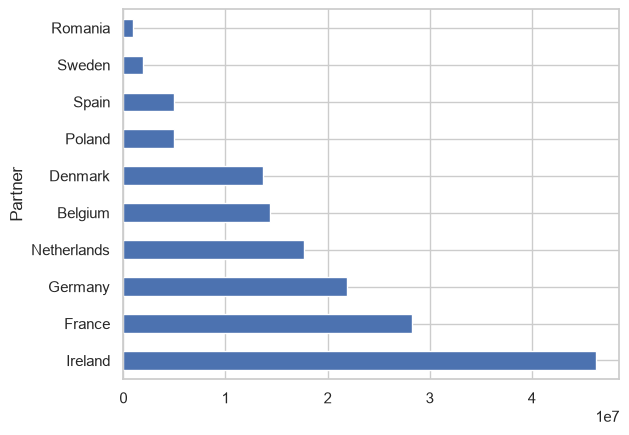

In [ ]:
totalImports.head(10).plot(kind='barh')

In [ ]:
exports = milk[milk[FLOW] == 'Exports']
grouped = exports.groupby([PARTNER])
print('The UK exports to', len(grouped), 'countries.')
print('The 5 biggest importers from the UK are:')
grouped[VALUE].aggregate(sum).sort_values(ascending=False,inplace=False).head()

The UK exports to 107 countries.
The 5 biggest importers from the UK are:


Partner
Ireland                 128155891
Netherlands              18018603
China                    14111163
Germany                  10828464
China, Hong Kong SAR      9482458
Name: Trade Value (US$), dtype: int64

## Regular importers

Given that there are two commodities, the third question, 'Which are the regular customers, i.e. which countries buy milk from the UK every month?', is meant in the sense that a regular customer imports both commodities every month. This means that if the exports dataframe is grouped by country, each group has exactly ten rows (two commodities bought each of the five months). To see the countries, only the first month of one commodity has to be listed, as by definition it's the same countries every month and for the other commodity.

In [ ]:
def buysEveryMonth(group):
    return len(group) == 10

grouped = exports.groupby([PARTNER])
regular = grouped.filter(buysEveryMonth)
regular[(regular[MONTH] == 201501) & (regular[COMMODITY] == 'processed')]

,Period,Partner,Trade Flow,Milk and cream,Trade Value (US$)
268,201501,Belgium,Exports,processed,142610
271,201501,China,Exports,processed,1013141
275,201501,Cyprus,Exports,processed,6625
280,201501,Denmark,Exports,processed,107883
284,201501,France,Exports,processed,178262
287,201501,Germany,Exports,processed,2588380
292,201501,"China, Hong Kong SAR",Exports,processed,1110086
294,201501,Hungary,Exports,processed,2119
298,201501,Ireland,Exports,processed,4020981
300,201501,Italy,Exports,processed,23267


Just over 75% of the total UK exports are due to these regular customers.

In [ ]:
regular[VALUE].sum() / exports[VALUE].sum()

np.float64(0.7583526396315317)

## Bi-directional trade

To address the fourth question,
'Which countries does the UK both import from and export to?', a pivot table is used to list the total export and import value for each country.

In [ ]:
countries = pivot_table(milk, index=[PARTNER], columns=[FLOW],
                        values=VALUE, aggfunc=sum)
countries.head()

Trade Flow,Exports,Imports
Partner,,
Algeria,8087885.0,NaN
Angola,2416129.0,NaN
Antigua and Barbuda,22218.0,NaN
"Areas, nes",51205.0,NaN
Australia,81644.0,NaN


Removing the rows with a missing value will result in only those countries with bi-directional trade flow with the UK.

In [ ]:
countries.dropna()

Trade Flow,Exports,Imports
Partner,,
Austria,56279.0,780.0
Belgium,7209121.0,14325697.0
Czech Rep.,2590.0,486889.0
Denmark,335068.0,13681759.0
France,9381762.0,28314091.0
Germany,10828464.0,21899123.0
Hungary,71378.0,4762.0
Ireland,128155891.0,46263897.0
Italy,173689.0,321635.0


In [ ]:
# Derive two new dataframes that separate out the 'World' partner data and the data for individual partner countries.

milk_world = milk[milk['Partner'] == 'World']
milk_countries = milk[milk['Partner'] != 'World']
milk_imports = milk[milk['Trade Flow'] == 'Imports']
milk_countries_imports = milk_countries[milk_countries['Trade Flow'] == 'Imports']
milk_world_imports=milk_world[milk_world['Trade Flow'] == 'Imports']

## Provide `1-Grouping & Aggregating Data/1.ipynb` Tasks Solutions below (Execute them)

Task

To complete these tasks you could copy this notebook and amend the code or create a new notebook to do the analysis for your chosen data.

Using the Comtrade Data website, identify a dataset that describes the import and export trade flows for a particular service or form of goods between your country (as reporter) and all ('All') the other countries in the world. Get the monthly data for all months in 2023.

In [ ]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import matplotlib
matplotlib.rcParams['axes.grid'] = True # show gridlines by default
%matplotlib inline

import pandas as pd

In [ ]:
# Load and inspect the CSV
import pandas as pd
LOCATION ='nigeria_petroleum_commodities_2023.csv'
petroleum_trade = pd.read_csv(LOCATION)
petroleum_trade.head(3)

,typeCode,freqCode,refPeriodId,Year,Month,Period,Reporter Code,Reporter ISO,Reporter,flowCode,...,isAltQtyEstimated,netWgt,isNetWgtEstimated,grossWgt,isGrossWgtEstimated,cifvalue,fobvalue,Trade Value (US$),isReported,isAggregate
0,C,M,20230101,2023,1,202301,566,NGA,Nigeria,M,...,False,NaN,False,0,False,2.330129e+09,NaN,2.330129e+09,False,True
1,C,M,20230101,2023,1,202301,566,NGA,Nigeria,M,...,False,0.9,False,0,False,1.455550e+02,NaN,1.455550e+02,False,True
2,C,M,20230101,2023,1,202301,566,NGA,Nigeria,M,...,False,494425210.8,True,0,False,5.277434e+08,NaN,5.277434e+08,False,True


In [ ]:
# sorting the columns
COLUMNS = [
    'Year', 'Period', 'Trade Flow', 'Reporter',
    'Partner', 'Commodity', 'Commodity Code',
    'Trade Value (US$)'
]

petroleum = petroleum_trade[COLUMNS].copy()

petroleum.head()

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
0,2023,202301,Import,Nigeria,World,Petroleum oils and oils from bituminous minera...,2710,2.330129e+09
1,2023,202301,Import,Nigeria,Austria,Petroleum oils and oils from bituminous minera...,2710,1.455550e+02
2,2023,202301,Import,Nigeria,Belgium,Petroleum oils and oils from bituminous minera...,2710,5.277434e+08
3,2023,202301,Import,Nigeria,China,Petroleum oils and oils from bituminous minera...,2710,2.807621e+04
4,2023,202301,Import,Nigeria,Costa Rica,Petroleum oils and oils from bituminous minera...,2710,1.072640e+02


In [ ]:
#Separate World totals from individual countries

petroleum_world = petroleum[petroleum['Partner'] == 'World']
petroleum_countries = petroleum[petroleum['Partner'] != 'World']

print('All records:', petroleum.shape)
print('World records:', petroleum_world.shape)
print('Individual partner records:', petroleum_countries.shape)

All records: (563, 8)
World records: (47, 8)
Individual partner records: (516, 8)


In [ ]:
#filtering and sorting, data subsetting
petroleum_imports = petroleum_countries[petroleum_countries['Trade Flow'] == 'Import']
petroleumImportsInJanuray = petroleum_imports[petroleum_imports['Period'] == 202301]
petroleumImportsInJanuray.sort_values('Trade Value (US$)', ascending=False).head(10)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
15,2023,202301,Import,Nigeria,Netherlands,Petroleum oils and oils from bituminous minera...,2710,5.351826e+08
2,2023,202301,Import,Nigeria,Belgium,Petroleum oils and oils from bituminous minera...,2710,5.277434e+08
12,2023,202301,Import,Nigeria,Rep. of Korea,Petroleum oils and oils from bituminous minera...,2710,3.795727e+08
18,2023,202301,Import,Nigeria,Russian Federation,Petroleum oils and oils from bituminous minera...,2710,1.567895e+08
19,2023,202301,Import,Nigeria,Saudi Arabia,Petroleum oils and oils from bituminous minera...,2710,1.169990e+08
20,2023,202301,Import,Nigeria,India,Petroleum oils and oils from bituminous minera...,2710,1.107314e+08
24,2023,202301,Import,Nigeria,Spain,Petroleum oils and oils from bituminous minera...,2710,1.072299e+08
17,2023,202301,Import,Nigeria,Norway,Petroleum oils and oils from bituminous minera...,2710,1.051136e+08
30,2023,202301,Import,Nigeria,United Kingdom,Petroleum oils and oils from bituminous minera...,2710,8.991347e+07
5,2023,202301,Import,Nigeria,Cyprus,Petroleum oils and oils from bituminous minera...,2710,5.733291e+07


In [ ]:
# EXPORT TRADE VALUES
petroleum_exports = petroleum_countries[petroleum_countries['Trade Flow'] == 'Export']

petroleumExportInJanuary = petroleum_exports[petroleum_exports['Period'] == 202301]
petroleumExportInJanuary.sort_values('Trade Value (US$)', ascending=False)

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
47,2023,202301,Export,Nigeria,Spain,Petroleum gases and other gaseous hydrocarbons,2711,2.396508e+08
49,2023,202301,Export,Nigeria,Türkiye,Petroleum gases and other gaseous hydrocarbons,2711,6.795006e+07
43,2023,202301,Export,Nigeria,"Other Asia, nes",Petroleum gases and other gaseous hydrocarbons,2711,4.910253e+07
40,2023,202301,Export,Nigeria,China,Petroleum gases and other gaseous hydrocarbons,2711,4.282799e+07
42,2023,202301,Export,Nigeria,Rep. of Korea,Petroleum gases and other gaseous hydrocarbons,2711,3.290896e+07
46,2023,202301,Export,Nigeria,Portugal,Petroleum gases and other gaseous hydrocarbons,2711,3.084196e+07
44,2023,202301,Export,Nigeria,Netherlands,Petroleum gases and other gaseous hydrocarbons,2711,2.082092e+07
48,2023,202301,Export,Nigeria,Thailand,Petroleum gases and other gaseous hydrocarbons,2711,2.015035e+07
41,2023,202301,Export,Nigeria,Jamaica,Petroleum gases and other gaseous hydrocarbons,2711,9.693153e+06
38,2023,202301,Export,Nigeria,"Areas, nes",Petroleum oils and oils from bituminous minera...,2710,2.547118e+06


## Provide `1-Grouping & Aggregating Data/2.ipynb` Tasks Solutions below (Execute them)

**Task 2**

Using your own data set from Exercise 1, try to group the data in a variety of ways, finding the most significant trade partner in each case:

by commodity, or commodity code

by trade flow, commodity and year.

In [ ]:
groups = petroleum_countries.groupby('Commodity Code')
groups.get_group(2710).sort_values('Trade Value (US$)', ascending=False).head()

,Year,Period,Trade Flow,Reporter,Partner,Commodity,Commodity Code,Trade Value (US$)
468,2023,202311,Import,Nigeria,Belgium,Petroleum oils and oils from bituminous minera...,2710,892359504.7
351,2023,202308,Import,Nigeria,Belgium,Petroleum oils and oils from bituminous minera...,2710,569376783.3
65,2023,202302,Import,Nigeria,Netherlands,Petroleum oils and oils from bituminous minera...,2710,537976094.9
15,2023,202301,Import,Nigeria,Netherlands,Petroleum oils and oils from bituminous minera...,2710,535182571.8
2,2023,202301,Import,Nigeria,Belgium,Petroleum oils and oils from bituminous minera...,2710,527743356.4


In [ ]:
# Find the biggest trade partner by commodity and trade flow

partner_by_commodity = (
    petroleum_countries
    .groupby(['Commodity Code', 'Trade Flow',], as_index=False)
    ['Trade Value (US$)']
    .sum()
)

top_partners = (
    partner_by_commodity
    .sort_values('Trade Value (US$)', ascending=False)
    .groupby(['Commodity Code', 'Trade Flow'])
    .head(1)
    .reset_index(drop=True)
)
top_partners

,Commodity Code,Trade Flow,Trade Value (US$)
0,2710,Import,2.011326e+10
1,2711,Export,6.492328e+09
2,2710,Export,1.103709e+08
3,2711,Import,2.952209e+07


In [ ]:
# . Group by trade flow, commodity, and year
trade_summary = (
    petroleum_countries
    .groupby(
        ['Trade Flow', 'Commodity Code', 'Year']
    )['Trade Value (US$)']
    .sum()
    .reset_index()
)

trade_summary

,Trade Flow,Commodity Code,Year,Trade Value (US$)
0,Export,2710,2023,1.103709e+08
1,Export,2711,2023,6.492328e+09
2,Import,2710,2023,2.011326e+10
3,Import,2711,2023,2.952209e+07


In [ ]:
# 4. Find the biggest partner by trade flow, commodity, and year
partner_summary = (
    petroleum_countries
    .groupby(
        ['Trade Flow', 'Commodity Code', 'Year', 'Partner']
    )['Trade Value (US$)']
    .sum()
    .reset_index()
)

top_partners_by_year = (
    partner_summary
    .sort_values('Trade Value (US$)', ascending=False)
    .groupby(
        ['Trade Flow', 'Commodity Code', 'Year']
    )
    .head(1)
    .reset_index(drop=True)
)

top_partners_by_year


,Trade Flow,Commodity Code,Year,Partner,Trade Value (US$)
0,Import,2710,2023,Belgium,5.294860e+09
1,Export,2711,2023,Spain,1.582841e+09
2,Export,2710,2023,"Areas, nes",4.125413e+07
3,Import,2711,2023,USA,1.844481e+07


## Provide `1-Grouping & Aggregating Data/3.ipynb` Tasks Solutions below (Execute them)

Task: Grouping data

As you complete the tasks, think about these questions:

For your particular dataset, how did you group the data and what questions did you ask of it?

Which countries were the major partners of your reporter country for the different groupings?

With the ability to group data so easily, what other sorts of questions would you like to be able to ask

In [ ]:
VAL = 'Trade Value (US$)'
d = petroleum_countries.copy()

def leaders(frame, keys):
    """Add up each partner's rows inside every group, then show the biggest partner of each group."""
    totals = frame.groupby(keys + ['Partner'])[VAL].sum().reset_index()    # one row per group and partner
    best = totals.loc[totals.groupby(keys)[VAL].idxmax()]                  # the biggest partner in each group
    return best.reset_index(drop=True)

print(leaders(d, ['Commodity Code']))                  # by commodity
print(leaders(d, ['Trade Flow']))                      # by flow
print(leaders(d, ['Trade Flow', 'Commodity Code']))    # by flow and commodity
print(leaders(d, ['Trade Flow', 'Commodity Code', 'Year']))   # adding year: only 2023, so no new groups
print(leaders(d, ['Trade Flow', 'Period']))            # by flow and month: does the leader change over the year?

   Commodity Code  Partner  Trade Value (US$)
0            2710  Belgium       5.294860e+09
1            2711    Spain       1.582841e+09
  Trade Flow  Partner  Trade Value (US$)
0     Export    Spain       1.582841e+09
1     Import  Belgium       5.294860e+09
  Trade Flow  Commodity Code     Partner  Trade Value (US$)
0     Export            2710  Areas, nes       4.125413e+07
1     Export            2711       Spain       1.582841e+09
2     Import            2710     Belgium       5.294860e+09
3     Import            2711         USA       1.844481e+07
  Trade Flow  Commodity Code  Year     Partner  Trade Value (US$)
0     Export            2710  2023  Areas, nes       4.125413e+07
1     Export            2711  2023       Spain       1.582841e+09
2     Import            2710  2023     Belgium       5.294860e+09
3     Import            2711  2023         USA       1.844481e+07
   Trade Flow  Period         Partner  Trade Value (US$)
0      Export  202301           Spain       2.396508

**How did I group the data, and what questions did I ask?**

I grouped by commodity, by trade flow, by flow and commodity together, and by flow and month. For each group I added up each partner's trade value and found the biggest partner, so that I could see whether the main partners differ by product, direction and time of year. Adding the year changed nothing, because the data covers only 2023.

**Which countries were the major partners for the different groupings?**
Belgium was the biggest import partner for commodity 2710 and Spain the biggest export partner for 2711. In one group, exports of 2710, the biggest entry was "Areas, nes". This means "not elsewhere specified", a bucket for trade that could not be assigned to a named country, so it is not a real partner. Leaving it out, the biggest named export partner for 2710 was Portugal, followed by the Netherlands and Togo. The leaders stayed the same when I added the year, because the data covers only 2023.

**What other questions would I like to ask?**
- How steady is each partner's trade from month to month?
- Which partner grew fastest over the year?
- How much of the total comes from the top three partners?

## Provide `1-Grouping & Aggregating Data/4.ipynb` Tasks Solutions below (Execute them)

Tasks

For the 0402 trade item, which months saw the greatest average (mean) activity? How does that compare with the maximum flows in each month? How does it compare with the total flow in each month?

Download your own choice of monthly dataset over one or two years containing both import and export data. (To start with, you may find it convenient to split the data into two dataframes, one for exports and one for imports.)

Using your own data:

find out which months saw the largest total value of imports, or exports?
assess, by eye, if there appears to be any seasonal trend in the behaviour of imports or exports?
plot a bar chart showing the top three importers or exporters of your selected trade item over the period you grabbed the data for, compared to the total world trade value.


                mean      max       sum
Period                                 
201501  1.129172e+06  6635455  33875174
201502  1.028683e+06  4906177  29831815
201503  1.135446e+06  4993292  31792486
201504  9.799299e+05  8473984  30377826
201505  1.133581e+06  7250526  30606677
Highest mean : 201503
Highest max  : 201504
Highest total: 201501


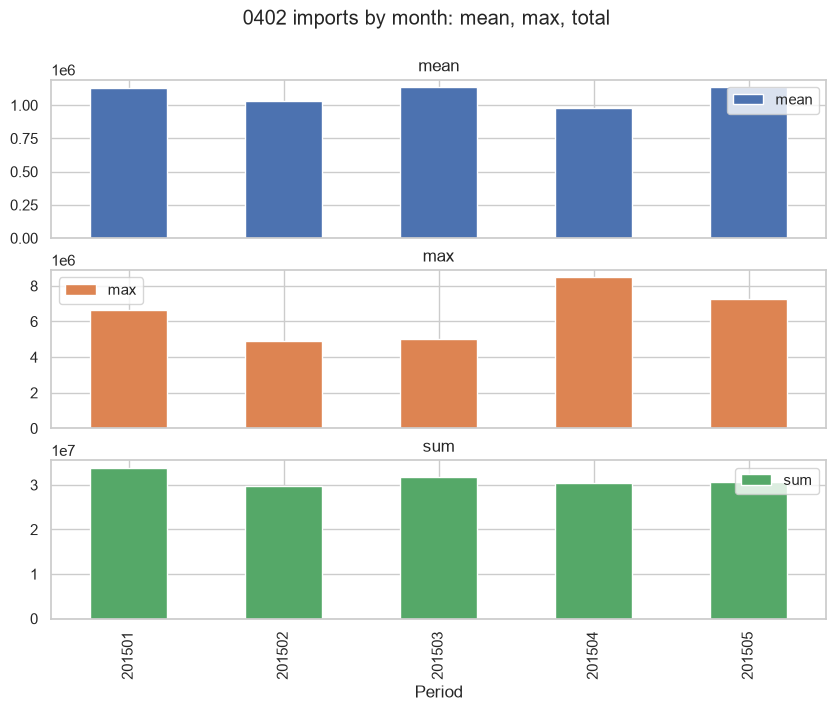

In [ ]:
# Keep the 0402 imports (the commodity code is text in this table)
imports = milk[milk['Trade Flow'] == 'Imports']

# One row per month: mean, maximum and total trade value
by_month = imports.groupby('Period')['Trade Value (US$)'].agg(['mean', 'max', 'sum'])
print(by_month)

# The best month under each measure
print('Highest mean :', by_month['mean'].idxmax())
print('Highest max  :', by_month['max'].idxmax())
print('Highest total:', by_month['sum'].idxmax())

by_month.plot(kind='bar', subplots=True, figsize=(10, 7), title='0402 imports by month: mean, max, total')
plt.show()


The month with the highest average flow was March 2015 1.14 million dollar, the largest single flow was in April 8.47 million dollar, and the highest total was in January `$33.9 million`. The three do not agree, April has the largest single flow but the lowest average, so one big shipment stood out in an otherwise ordinary month. The monthly averages are close to each other from about `$0.98 to $1.14 million`, so the monthly total depends mostly on how many records the month has: January has 30, while March, with the highest average, has only 28.

Trade Flow        Export        Import
Period                                
202301      5.181372e+08  2.330758e+09
202302      4.267771e+08  1.877938e+09
202303      5.437183e+08  2.206028e+09
202304      4.501719e+08  1.961814e+09
202305      4.622652e+08  1.649315e+09
202306      5.234252e+08  8.718006e+08
202307      3.850764e+08  1.231936e+09
202308      5.273254e+08  1.703563e+09
202309      5.707168e+08  1.511166e+09
202310      3.775729e+08  1.247052e+09
202311      9.290385e+08  2.126365e+09
202312      8.884740e+08  1.425042e+09
Largest import month: 202301 | lowest: 202306
Largest export month: 202311 | lowest: 202310


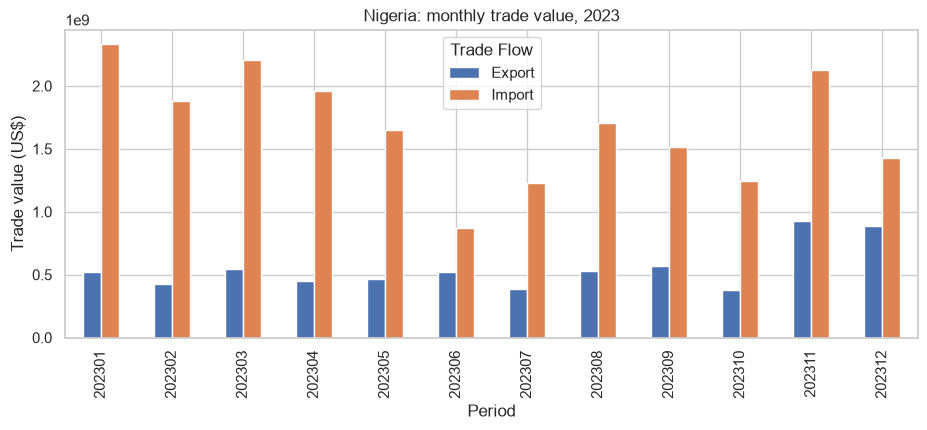

In [ ]:
# (b) Months with the largest total imports and exports, and seasonality by eye:

d = petroleum_countries.copy()

# Total value for each month and flow, imports and exports side by side
monthly = d.groupby(['Period', 'Trade Flow'])[VAL].sum().unstack('Trade Flow')
print(monthly)

print('Largest import month:', monthly['Import'].idxmax(), '| lowest:', monthly['Import'].idxmin())
print('Largest export month:', monthly['Export'].idxmax(), '| lowest:', monthly['Export'].idxmin())

monthly.plot(kind='bar', figsize=(11, 4), title='Nigeria: monthly trade value, 2023')
plt.ylabel('Trade value (US$)'); plt.show()

Imports were largest in `201501` and smallest in `201506`; exports were largest in `201511` and smallest in `201507`. these appears to be that the months imports pattern just vary irregularly while the exports is more like a steady flow with sharp peak towards the last two month of 2015.

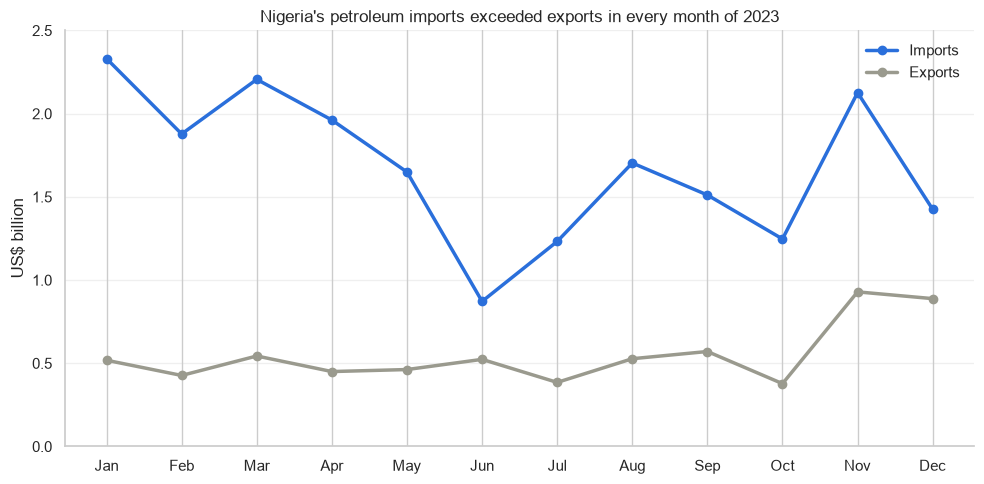

In [ ]:
import matplotlib.pyplot as plt

b = monthly / 1e9                                   # convert US$ to US$ billion
b.index = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(b.index, b['Import'], marker='o', linewidth=2.5, color='#2a6fdb', label='Imports')
ax.plot(b.index, b['Export'], marker='o', linewidth=2.5, color='#9a9a8e', label='Exports')
ax.set_title("Nigeria's petroleum imports exceeded exports in every month of 2023")
ax.set_ylabel('US$ billion')
ax.set_ylim(0, 2.5)
ax.grid(axis='y', alpha=0.3)
ax.legend(frameon=False)
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)          # cleaner look
plt.tight_layout()
plt.savefig('nigeria_monthly_trade.png', dpi=200, facecolor='white')   # save BEFORE show()
plt.show()

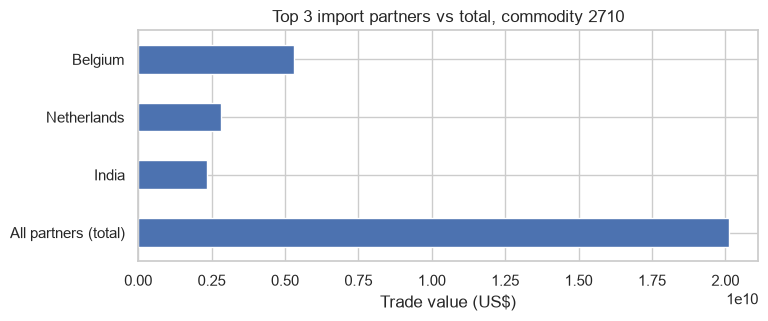

Import - top 3 share of the total: 52.1 %


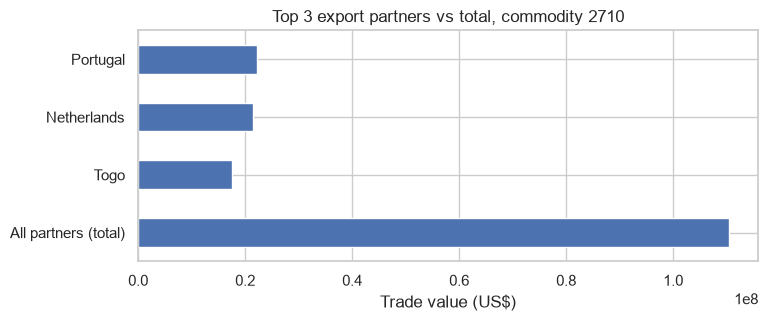

Export - top 3 share of the total: 55.4 %


In [ ]:
#Bar chart: the top three partners against the total:

item = 2710

for flow in ['Import', 'Export']:
    sub = d[(d['Trade Flow'] == flow) & (d['Commodity Code'] == item)]
    by_partner = sub.groupby('Partner')[VAL].sum().sort_values(ascending=False)

    # Name only real countries: leave the 'Areas, nes' bucket out of the top three
    top3 = by_partner.drop('Areas, nes', errors='ignore').head(3)

    # The total is every partner's rows added up (this download has no World row)
    chart = pd.concat([top3, pd.Series({'All partners (total)': by_partner.sum()})])

    chart.plot(kind='barh', figsize=(8, 3), title=f'Top 3 {flow.lower()} partners vs total, commodity {item}')
    plt.gca().invert_yaxis(); plt.xlabel('Trade value (US$)'); plt.show()

    print(flow, '- top 3 share of the total:', round(top3.sum() / by_partner.sum() * 100, 1), '%')

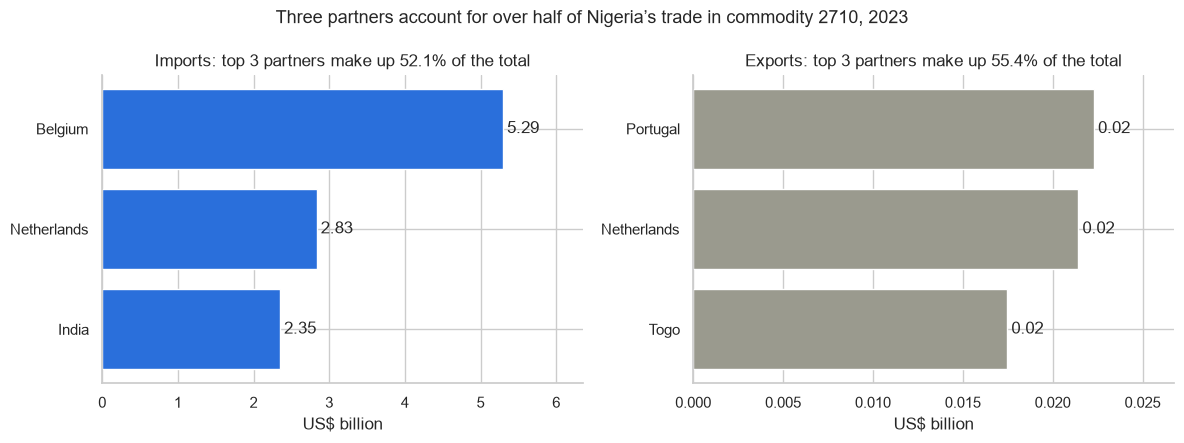

In [ ]:
item = 2710                                     # your trade item

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, flow in zip(axes, ['Import', 'Export']):
    # Total value for each partner, within this flow and commodity
    sub = d[(d['Trade Flow'] == flow) & (d['Commodity Code'] == item)]
    by_partner = sub.groupby('Partner')[VAL].sum().sort_values(ascending=False)

    # Top three real countries: leave out the 'Areas, nes' bucket, but keep it in the total
    top3 = by_partner.drop('Areas, nes', errors='ignore').head(3)
    share = top3.sum() / by_partner.sum() * 100

    # Reverse the order so the biggest bar is at the top
    bars = ax.barh(top3.index[::-1], top3.values[::-1] / 1e9,
                   color='#2a6fdb' if flow == 'Import' else '#9a9a8e')
    ax.bar_label(bars, fmt='%.2f', padding=3)          # print each value at the end of its bar
    ax.set_title(f'{flow}s: top 3 partners make up {share:.1f}% of the total')
    ax.set_xlabel('US$ billion')
    ax.set_xlim(0, top3.max() / 1e9 * 1.2)             # leave room for the value labels
    for side in ['top', 'right']:
        ax.spines[side].set_visible(False)             # cleaner look

fig.suptitle('Three partners account for over half of Nigeria\u2019s trade in commodity 2710, 2023', fontsize=13)
plt.tight_layout()
plt.savefig('nigeria_top_partners.png', dpi=200, facecolor='white')   # save BEFORE show()
plt.show()

The top three import partners for commodity 2710 were `Belgium, Netherlands, India` making up 52.1% of total imports while for export partners they were `Portugal, Netherlands, Togo`, together making up 55.4% of the total exports, sSo trade in this item is concentrated in a few partners, three countries account for over half of each flow.

1. **Highest and lowest months:**

imports peaked in January (about $2.33 billion) and were lowest in June (about $0.87 billion); exports peaked in November (about $0.93 billion) and were lowest in October (about $0.38 billion).

2. **Seasonal behaviour:**

imports appear higher in the first months of the year and in November, with a low in June. Exports appear steady until a rise in November and December. One year cannot show whether this repeats.

3. **Do any partners dominate?**

Three partners make up 52.1% of imports and 55.4% of exports of commodity 2710, compared with the total, so a few countries dominate trade in this item.

## Conclusions

The milk and cream trade of the UK from January to May 2015 was analysed in terms of which countries the UK mostly depends on for income (exports) and goods (imports). Over the period, the UK had a trade surplus of over 100 million US dollars.

Ireland is the main partner, but it imported from the UK almost the triple in value than it exported to the UK.

The UK exported to over 100 countries during the period, but only imported from 21 countries, the main ones (top five by trade value) being geographically close. China and Hong Kong are the main importers that are not also main exporters.

The UK is heavily dependent on its regular customers, the 16 countries that buy all types of milk and cream every month. They contribute three quarters of the total export value.

The UK has bi-directional trade (i.e. both exports and imports) with 20 countries, although for some the trade value (in US dollars) is suspiciously low, which raises questions about the data's accuracy.


## Now repeat the analysis with your own data gotten from Comtrade website

## Exploring Nigeria's trade in petroleum products, 2023
Using UN Comtrade data, I analyse Nigeria's imports and exports of commodities 2710 and 2711 in 2023. The questions follow the UK milk project:
1. How much does Nigeria import and export, and is the balance positive?
2. Who are the main trading partners?
3. Which partners trade every month?
4. Which partners does Nigeria both import from and export to?

**Cleaning:** the download had no `World` row to remove. It does contain "Areas, nes" entries, a bucket for trade that could not be assigned to a named country, so I remove them to avoid ranking a bucket as if it were a country.

In [ ]:
VAL = 'Trade Value (US$)'
d = petroleum_countries[petroleum_countries['Partner'] != 'Areas, nes'].copy()   # drop the unspecified bucket
print(petroleum_countries.shape, '->', d.shape)     # shows how many rows the bucket held

(516, 8) -> (503, 8)


### 1. Total trade and the balance
Group by trade flow and add up the values. The balance is exports minus imports: positive means Nigeria sells more than it buys.

In [ ]:
tot = d.groupby('Trade Flow')[VAL].sum()
print(tot)
print('Balance (exports - imports):', tot['Export'] - tot['Import'])

Trade Flow
Export    6.532073e+09
Import    2.014278e+10
Name: Trade Value (US$), dtype: float64
Balance (exports - imports): -13610704905.425999


##### 2. Main trading partners
For each flow, add up each partner's monthly values (adding first matters, because one partner has many rows) and sort. A bar chart shows the gaps between partners.

Import | partners: 60
Partner
Belgium               5.294860e+09
Netherlands           2.833255e+09
India                 2.347697e+09
Malta                 1.920412e+09
Russian Federation    1.237551e+09
Name: Trade Value (US$), dtype: float64 



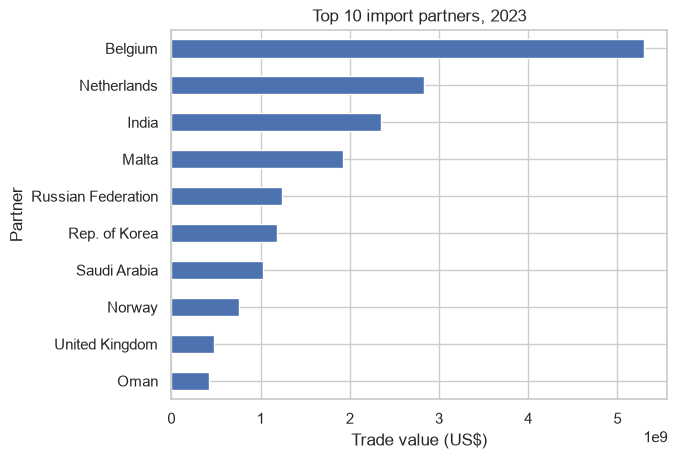

Top 3 share of the flow: 52.0 %

Biggest partner share: 26.3 %
Export | partners: 30
Partner
Spain            1.582841e+09
China            6.592813e+08
Portugal         6.402625e+08
USA              5.861031e+08
Rep. of Korea    5.325753e+08
Name: Trade Value (US$), dtype: float64 



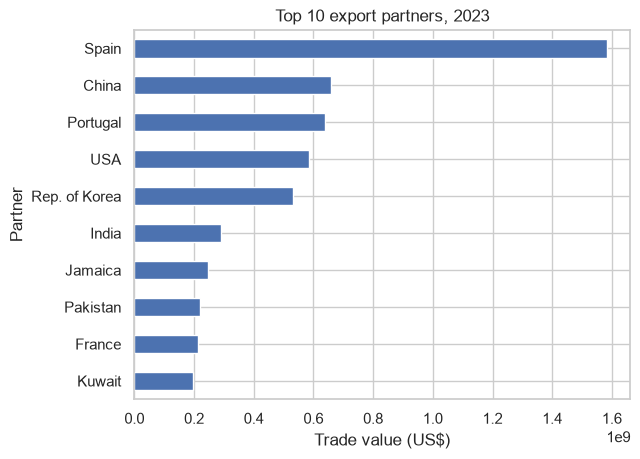

Top 3 share of the flow: 44.1 %

Biggest partner share: 24.2 %


In [ ]:
for flow in ['Import', 'Export']:
    totals = d[d['Trade Flow'] == flow].groupby('Partner')[VAL].sum().sort_values(ascending=False)
    print(flow, '| partners:', len(totals))
    print(totals.head(5), '\n')
    totals.head(10).plot(kind='barh', title=f'Top 10 {flow.lower()} partners, 2023').invert_yaxis()   # biggest bar at the top
    plt.xlabel('Trade value (US$)'); plt.show()
    print('Top 3 share of the flow:', round(totals.head(3).sum() / totals.sum() * 100, 1), '%\n')
    print('Biggest partner share:', round(totals.iloc[0] / totals.sum() * 100, 1), '%')

 3. Regular partners

In the UK project, a "regular customer" bought every month. Here, a regular export partner is one that appears in all 12 months of 2023. I count the months each partner appears in, then find how much of the export value those partners account for.

In [ ]:
exp = d[d['Trade Flow'] == 'Export']
months = exp.groupby('Partner')['Period'].nunique()          # number of different months each partner appears in
print(months.value_counts().sort_index())                    # how many partners appear in 1, 2, ... 12 months

regular = months[months == 12].index                         # if this is empty, loosen 12 to 10 and say so
share = exp[exp['Partner'].isin(regular)][VAL].sum() / exp[VAL].sum() * 100
print(len(regular), 'regular partners, making up', round(share, 1), '% of exports')
print(list(regular))

Period
1     8
2     2
3     5
4     2
5     4
6     1
7     1
8     1
9     1
11    4
12    1
Name: count, dtype: int64
1 regular partners, making up 24.2 % of exports
['Spain']


**4. Partners in both directions**

A pivot table puts imports and exports side by side for each partner. Partners with a missing value on either side only trade one way, so dropping them leaves the two-way partners.

In [ ]:
pivot = d.pivot_table(index='Partner', columns='Trade Flow', values=VAL, aggfunc='sum')
both = pivot.dropna()
print(len(both), 'of', len(pivot), 'partners trade both ways')
both.sort_values('Import', ascending=False).head(10)

20 of 70 partners trade both ways


Trade Flow,Export,Import
Partner,,
Belgium,1.784649e+08,5.294860e+09
Netherlands,1.870698e+08,2.833255e+09
India,2.887218e+08,2.347697e+09
Rep. of Korea,5.325753e+08,1.187947e+09
United Kingdom,1.601706e+08,4.750623e+08
France,2.144508e+08,3.078609e+08
United Arab Emirates,4.087021e+07,2.833818e+08
Türkiye,1.581592e+08,2.786971e+08
"Other Asia, nes",9.200795e+07,2.615665e+08


## Conclusions
- **Balance:** Nigeria's imports were larger than its exports, about $20.14 billion against $6.53 billion, giving a trade deficit of about $13.61 billion. Imports were roughly three times the value of exports.
- **Main partners:** the biggest import partner was Belgium, with [26.3]% of imports, and the biggest export partner was Spain, with [24.2]% of exports. Spain's export value was larger than the next two partners combined, so exports depend heavily on one partner.
- **Regular partners:** only 1 partner traded in every month of 2023 [Spain], making up [24.2]% of exports.
- **Two-way trade:** 20 partners were both import and export partners, including Belgium, India, the Netherlands and the United Kingdom.
- **Concerns:** the data contains an "Areas, nes" entry, a bucket for trade that could not be assigned to a named country, which I removed so it would not be ranked as a country. Trade is very uneven: even Oman, one of the top 10 import partners, traded less than half a billion dollars. Most partners trade irregularly: 8 partners appear in only in month 01. But the data is too small to say whether this pattern is typical.

In [ ]:
# Calculate monthly imports and exports across both petroleum commodities
monthly_trade = (
    petroleum_countries
    .groupby(['Period', 'Trade Flow'])['Trade Value (US$)']
    .sum()
    .unstack(fill_value=0)
)

# Convert values from dollars to billions of dollars
monthly_trade = monthly_trade / 1_000_000_000

# Calculate the monthly trade balance
monthly_trade['Balance'] = (
    monthly_trade['Export'] - monthly_trade['Import']
)

print(monthly_trade.round(2))

Trade Flow  Export  Import  Balance
Period                             
202301        0.52    2.33    -1.81
202302        0.43    1.88    -1.45
202303        0.54    2.21    -1.66
202304        0.45    1.96    -1.51
202305        0.46    1.65    -1.19
202306        0.52    0.87    -0.35
202307        0.39    1.23    -0.85
202308        0.53    1.70    -1.18
202309        0.57    1.51    -0.94
202310        0.38    1.25    -0.87
202311        0.93    2.13    -1.20
202312        0.89    1.43    -0.54


---
# Part B: Data Visualization

Add your seaborn/matplotlib plots below. Use the milk trade data from Part A. Give each plot a title and labelled axes, and write one sentence under it saying what it shows.

In [ ]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

sns.set_theme(style='whitegrid')
# clean grid background for every chart
VALUE, FLOW, PARTNER, MONTH = 'Trade Value (US$)', 'Trade Flow', 'Partner', 'Period'

# Log scales cannot show zero or negative values, so keep a copy with positive values only
pos = milk[milk[VALUE] > 0]
print(milk.shape, pos.shape)

(617, 5) (617, 5)


 Part B: Data Visualization

These plots use the UK milk trade data from Part A (World rows removed). Trade values range from a few dollars to millions, so most plots use a logarithmic scale: without it, the few very large values would squash everything else into one corner.

## 1. Histogram: how big are individual trade flows?
A histogram counts how many records fall into each value range (bin). I want to know whether most flows are small or large.

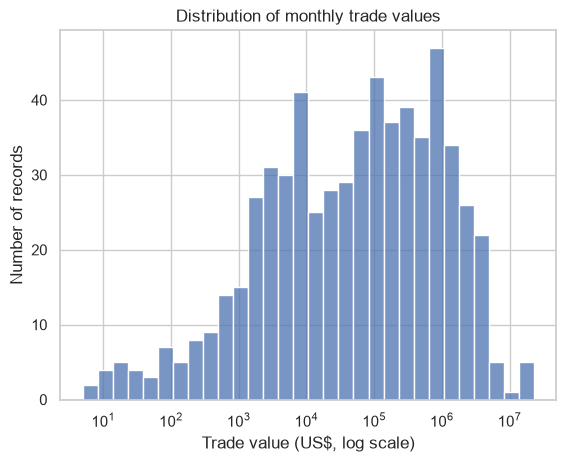

In [ ]:
sns.histplot(data=pos, x=VALUE, bins=30, log_scale=True)   # log_scale=True: each bin covers a multiple of the last
plt.title('Distribution of monthly trade values')
plt.xlabel('Trade value (US$, log scale)')
plt.ylabel('Number of records')
plt.show()

**What it shows:** Most flows are around $1,000,000, with a small number of very large flows above $10 million

## 2. KDE plot: imports against exports
A KDE (kernel density estimate) is a smoothed histogram. Drawing one curve per trade flow lets me compare the two shapes directly. `common_norm=False` scales each curve on its own, so a flow with fewer records is not flattened.

In [ ]:
# Count distinct trading partners for imports and exports
partner_counts = (
    milk_countries
    .groupby('Trade Flow')['Partner']
    .nunique()
)

print(partner_counts)

Trade Flow
Exports    107
Imports     21
Name: Partner, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

# Select export records
exports = milk_countries[
    milk_countries['Trade Flow'] == 'Exports'
].copy()

# Remove zero and negative values before applying log10
exports = exports[exports['Trade Value (US$)'] > 0]

# Create logarithmic value bands
exports['value_band'] = pd.cut(
    np.log10(exports['Trade Value (US$)']),
    bins=[-np.inf, 3, 4, 5, 6, 7, np.inf],
    labels=[
        'Below $1,000',
        '$1,000–$9,999',
        '$10,000–$99,999',
        '$100,000–$999,999',
        '$1m–$9.9m',
        '$10m and above'
    ]
)

print(exports['value_band'].value_counts().sort_index())

value_band
Below $1,000          55
$1,000–$9,999        117
$10,000–$99,999      110
$100,000–$999,999    138
$1m–$9.9m             47
$10m and above         5
Name: count, dtype: int64


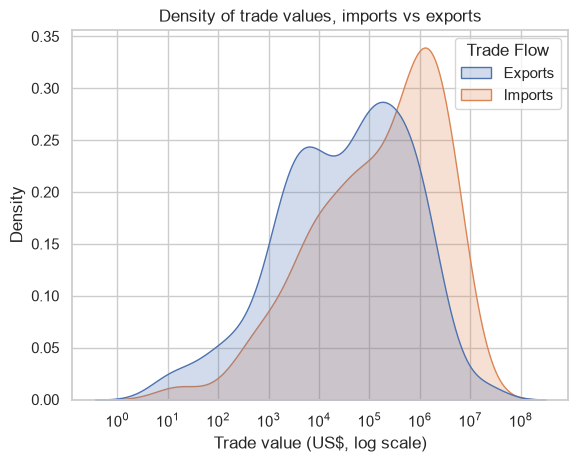

In [ ]:
sns.kdeplot(data=pos, x=VALUE, hue=FLOW, log_scale=True, common_norm=False, fill=True)
plt.title('Density of trade values, imports vs exports')
plt.xlabel('Trade value (US$, log scale)')
plt.show()

**What it shows:** Import flows typically peak at around $1 million, while export flows have two peaks, around $10,000 and $100,000, so exports are typically smaller and made up of two groups of flows. This is probably because the UK exports to many more countries than it imports from, but i haven't test the reason

 3. Box and violin plots: spread of each flow
A box plot shows the median, the middle half of the values and the outliers. A violin plot adds the full shape of the distribution. I draw both side by side so I can compare them.

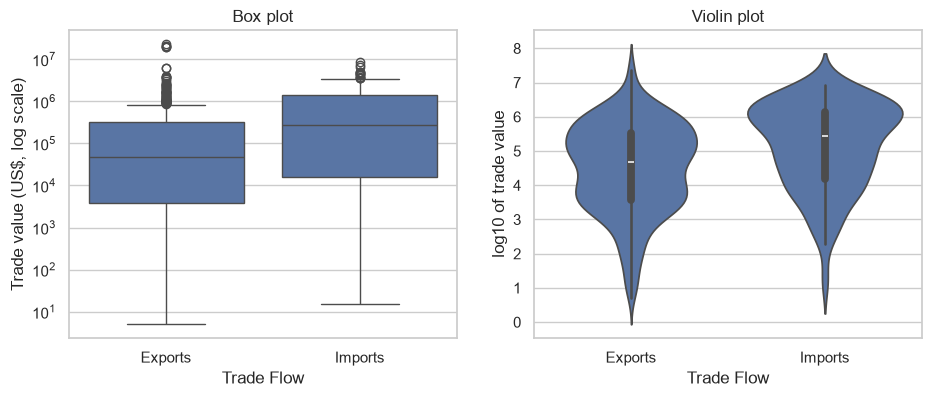

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(data=pos, x=FLOW, y=VALUE, ax=ax[0])
ax[0].set_yscale('log')                                  # log axis for the box plot
ax[0].set_title('Box plot'); ax[0].set_ylabel('Trade value (US$, log scale)')

# the violin plot has no log axis option, so I plot the log10 of the values instead
sns.violinplot(x=pos[FLOW], y=np.log10(pos[VALUE]), ax=ax[1])
ax[1].set_title('Violin plot'); ax[1].set_ylabel('log10 of trade value')
plt.show()

**What it shows:** The median export flow is higher than the median import flow, and Export flow has more extreme values.

4. Regression plot: do countries that sell to the UK also buy from it?

Each dot is one partner country: its total imports (x) against its total exports (y), only for countries that appear in both directions. The line is the best straight-line fit. A correlation does not show that one causes the other.

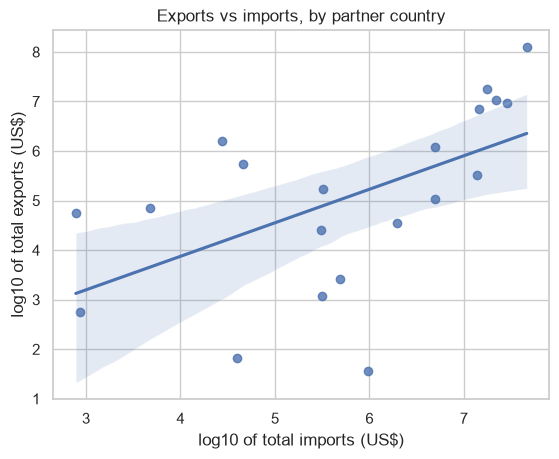

20 partners | Spearman correlation: 0.65 | p = 0.0021


In [ ]:
# One row per partner, imports and exports side by side; keep only partners with both
totals = pos.pivot_table(index=PARTNER, columns=FLOW, values=VALUE, aggfunc='sum').dropna()

sns.regplot(x=np.log10(totals['Imports']), y=np.log10(totals['Exports']))
plt.title('Exports vs imports, by partner country')
plt.xlabel('log10 of total imports (US$)')
plt.ylabel('log10 of total exports (US$)')
plt.show()

corr, p = spearmanr(totals['Imports'], totals['Exports'])      # rank correlation, as in Week 7
print(len(totals), 'partners | Spearman correlation:', round(corr, 2), '| p =', round(p, 4))

**What it shows:** Across the 20 partners that trade in both directions, the correlation between imports and exports is 0.65 and statistically significant, so partners that sell more to the UK tend to buy more from it.

 5. Heatmap: the biggest export partners, month by month

A heatmap shows a table as colours, so I can see which partner and month combinations are largest. I show the 10 biggest export partners, in millions of US$.

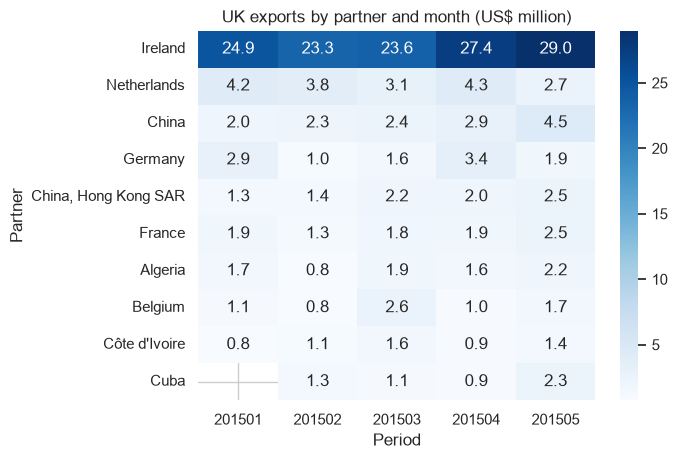

In [ ]:
exp = milk[milk[FLOW] == 'Exports']
top = exp.groupby(PARTNER)[VALUE].sum().nlargest(10).index            # the 10 biggest by total value

table = (exp[exp[PARTNER].isin(top)]
         .pivot_table(index=PARTNER, columns=MONTH, values=VALUE, aggfunc='sum') / 1e6)
table = table.loc[top]                                                  # keep the biggest partner at the top

sns.heatmap(table, annot=True, fmt='.1f', cmap='Blues')               # annot prints each value in its cell
plt.title('UK exports by partner and month (US$ million)')
plt.show()

**What it shows:** Ireland is the biggest export partner, and its trade is steady across the months, with month `05` the highest overall.

<!-- practice:start -->
---
## 🔁 SQL Practice

This week you split, applied and combined the UK milk-trade data with `groupby` and `pivot_table`, then plotted it. Now answer the same kind of questions **in SQL**, straight from the `week09` tables: `GROUP BY` is SQL's split-apply-combine.

**How it works**
1. Run the **practice setup** cell first (and again after restarting the kernel). It connects with your **read-only** account.
2. **SQL tasks:** write your query between the triple quotes and run the cell. `p.sql(...)` shows your result and
   says ✅ or ❌, and whether the **shape** (rows × columns) is right. Match the column order, sort order and rounding
   asked for (column *names* aren't checked).
3. Run `p.score()` at the end to see your practice score.

Refresh your memory with `Week-6 (Numpy & Pandas-1)/4-Intermediate SQL/Intermediate SQL.ipynb`.

In [ ]:
# --- practice setup: run this cell first (don't edit it) ---
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.practice import Practice, q

EXPECTED = {
 "s01": [
  [
   4,
   4
  ],
  "58c6ed3aa1049eff4acfe5edcb59b1d51d4a45f3579bb7c1db90ae2724f0e865"
 ],
 "s02": [
  [
   12,
   4
  ],
  "cf8e205c894ca889a22c89cfce94e601860d25931f62e999f4408800c74d8280"
 ],
 "s03": [
  [
   10,
   3
  ],
  "d6dcb9773bc969b74418a8b0a4bcc92581bf839100b25d7b16d2710934ca53d8"
 ],
 "s04": [
  [
   6,
   5
  ],
  "d940a4dfa48898fdeea545a6f4a693d039a8601cb0ad38d9f20bab0e641840d1"
 ],
 "s05": [
  [
   30,
   4
  ],
  "92f2c46acfb66aa693f51c79b678dbfed4d60714ebfb6c6a3a5d08e585879061"
 ]
}   # fingerprints only: the answers are not stored here
TITLES = {
 "s01": "Split-apply-combine: GROUP BY two columns",
 "s02": "A monthly imports vs exports table",
 "s03": "Subtotals with GROUPING SETS",
 "s04": "Top 3 partners per trade flow (window function)",
 "s05": "A tidy table for a stacked bar chart"
}
p = Practice(EXPECTED, TITLES)
print(f"Practice ready: {len(TITLES)} tasks. Connected as:", q("SELECT CURRENT_USER AS u").u[0])

Practice ready: 5 tasks. Connected as: intern_readonly


### SQL Task 1 · Split-apply-combine: GROUP BY two columns

Use the 2015 data, `week09.comtrade_milk_uk_jan_jul_15` (it covers January–May 2015). Group it by **trade flow** and
**milk type**, like the lesson's `milk.groupby([FLOW, COMMODITY])`. The milk type comes from the commodity code:
`'0401'` → `'unprocessed'`, `'0402'` → `'processed'`.

**Return:** `trade_flow`, `milk_type`, `partners` (how many **different** partner countries), `total_musd` (total
trade value in **millions** of US$, **rounded to 2 dp**). Sort by `trade_flow`, then `milk_type` (both A→Z).
⚠️ Remove the `Partner = 'World'` rows first: they are monthly totals, so keeping them counts everything twice.
💡 `CASE [Commodity Code] WHEN '0401' THEN ... END`, `COUNT(DISTINCT Partner)`, and `GROUP BY` the same `CASE`
expression.

In [ ]:
SQL_01 = """
SELECT
    [Trade Flow] AS trade_flow,
    CASE
        WHEN [Commodity Code] = '0401' THEN 'unprocessed'
        WHEN [Commodity Code] = '0402' THEN 'processed'
        ELSE 'unknown'
    END AS milk_type,
    COUNT(DISTINCT Partner) AS partners,
    ROUND(SUM([Trade Value (US$)]) / 1000000.0, 2) AS total_musd
FROM week09.comtrade_milk_uk_jan_jul_15
WHERE Partner <> 'World'
GROUP BY
    [Trade Flow],
    CASE
        WHEN [Commodity Code] = '0401' THEN 'unprocessed'
        WHEN [Commodity Code] = '0402' THEN 'processed'
        ELSE 'unknown'
    END
ORDER BY
    trade_flow,
    milk_type;

"""
p.sql("s01", SQL_01)

,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


✅ s01: correct!


,trade_flow,milk_type,partners,total_musd
0,Exports,processed,95,131.96
1,Exports,unprocessed,51,133.07
2,Imports,processed,19,88.08
3,Imports,unprocessed,17,68.40


### SQL Task 2 · A monthly imports vs exports table

`week09.countrymilk` is the clean 2014 data: one row per month, flow, partner and commodity, with the
`'World'` rows already removed. Build the table that `pivot_table(index='Period', columns='Trade Flow', ...)` gives you,
but in SQL: **one row per month**, imports and exports side by side, plus the trade balance.

**Return:** `period` (e.g. `201401`), `imports_musd`, `exports_musd`, `balance_musd` (exports − imports), all in
**millions of US$, rounded to 2 dp**. Sort by `period`.
⚠️ Work out the balance from the **unrounded** sums and round only at the end (rounding first can be 0.01 off).
💡 Conditional aggregation: `SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END)`. `PIVOT`
works too. Look at the result: is the balance positive in every month?

In [ ]:
SQL_02 = """
SELECT
    Period AS period,
    -- conditional aggregation: add up only the rows of one flow
    ROUND(SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END) / 1e6, 2) AS imports_musd,
    ROUND(SUM(CASE WHEN [Trade Flow] = 'Exports' THEN [Trade Value (US$)] ELSE 0 END) / 1e6, 2) AS exports_musd,
    -- balance from the UNROUNDED sums, rounded only at the end
    ROUND((SUM(CASE WHEN [Trade Flow] = 'Exports' THEN [Trade Value (US$)] ELSE 0 END)
         - SUM(CASE WHEN [Trade Flow] = 'Imports' THEN [Trade Value (US$)] ELSE 0 END)) / 1e6, 2) AS balance_musd
FROM week09.countrymilk
GROUP BY Period
ORDER BY Period
"""
p.sql("s02", SQL_02)

,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


✅ s02: correct!


,period,imports_musd,exports_musd,balance_musd
0,201401,52.37,87.14,34.76
1,201402,39.30,72.49,33.19
2,201403,44.32,86.78,42.46
3,201404,44.21,95.20,50.99
4,201405,48.08,96.20,48.13
5,201406,45.10,99.32,54.21
6,201407,44.80,72.88,28.08
7,201408,40.29,61.74,21.44
8,201409,56.70,60.60,3.90
9,201410,56.37,57.00,0.64


### SQL Task 3 · Subtotals with GROUPING SETS

A manager wants a **quarterly report for 2014** (`week09.countrymilk`) with a **year subtotal** under each trade
flow, in one query.

**Return:** `trade_flow`, `quarter` (`'Q1'` … `'Q4'`, or `'Year'` on the subtotal row), `total_musd` (millions of
US$, **rounded to 2 dp**). That is 10 rows: for each flow, Q1–Q4 and then its `'Year'` row. Sort by `trade_flow`
(A→Z), then the quarters in order, with the `'Year'` row last.
💡 Quarter from `Period`: `(Period % 100 + 2) / 3` gives 1–4 (integer division). Then
`GROUP BY GROUPING SETS ((flow, quarter), (flow))`, and `GROUPING(quarter) = 1` tells you a row is a subtotal.
⚠️ Don't add a grand total over both flows: adding imports to exports is not a meaningful number.

In [ ]:
SQL_03 = """
WITH qtr_rows AS (
    SELECT
        [Trade Flow] AS trade_flow,
        -- month number is the last two digits of Period; (month + 2) / 3 gives the quarter 1-4
        'Q' + CAST((CAST(Period AS int) % 100 + 2) / 3 AS varchar(1)) AS qtr,
        [Trade Value (US$)] AS v
    FROM week09.countrymilk
)
SELECT
    trade_flow,
    CASE WHEN GROUPING(qtr) = 1 THEN 'Year' ELSE qtr END AS quarter,   -- GROUPING = 1 marks the subtotal row
    ROUND(SUM(v) / 1e6, 2) AS total_musd
FROM qtr_rows
GROUP BY GROUPING SETS ((trade_flow, qtr), (trade_flow))               -- per quarter, and per flow for the year
ORDER BY trade_flow, GROUPING(qtr), qtr
"""
p.sql("s03", SQL_03)

,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


✅ s03: correct!


,trade_flow,quarter,total_musd
0,Exports,Q1,246.41
1,Exports,Q2,290.71
2,Exports,Q3,195.22
3,Exports,Q4,166.31
4,Exports,Year,898.65
5,Imports,Q1,135.99
6,Imports,Q2,137.39
7,Imports,Q3,141.79
8,Imports,Q4,148.71
9,Imports,Year,563.88


### SQL Task 4 · Top 3 partners per trade flow (window function)

Project 4 asks: *which are the main trading partners?* Answer it for **both flows at once** using 2014
(`week09.countrymilk`): the **top 3 partners by total trade value in each trade flow**, and each partner's share of
that flow's total.

**Return:** `trade_flow`, `rank` (1–3), `partner`, `total_musd` (millions of US$, **rounded to 2 dp**), `share_pct`
(the partner's % of **its flow's** total over all partners, **rounded to 1 dp**). Sort by `trade_flow`, then `rank`.
💡 First total per (flow, partner) in a CTE. Then `ROW_NUMBER() OVER (PARTITION BY flow ORDER BY total DESC,
partner)` and `SUM(total) OVER (PARTITION BY flow)` for the share. Filter `rank <= 3` in the outer query (you can't
filter on a window function in the same `WHERE`).

In [ ]:
SQL_04 = """
WITH totals AS (                                   -- step 1: total value per flow and partner
    SELECT [Trade Flow] AS trade_flow, Partner, SUM([Trade Value (US$)]) AS total
    FROM week09.countrymilk
    GROUP BY [Trade Flow], Partner
),
ranked AS (                                        -- step 2: rank within each flow, and the flow's total
    SELECT trade_flow, Partner, total,
           ROW_NUMBER() OVER (PARTITION BY trade_flow ORDER BY total DESC, Partner) AS rnk,
           SUM(total)   OVER (PARTITION BY trade_flow) AS flow_total
    FROM totals
)
SELECT trade_flow,
       rnk AS [rank],
       Partner AS partner,
       ROUND(total / 1e6, 2) AS total_musd,
       ROUND(100.0 * total / flow_total, 1) AS share_pct   -- share of the flow's total across ALL partners
FROM ranked
WHERE rnk <= 3                                     -- filter outside: a window result can't be used in the same WHERE
ORDER BY trade_flow, rnk
"""
p.sql("s04", SQL_04)

,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


✅ s04: correct!


,trade_flow,rank,partner,total_musd,share_pct
0,Exports,1,Ireland,421.23,46.9
1,Exports,2,Algeria,93.75,10.4
2,Exports,3,Netherlands,68.65,7.6
3,Imports,1,Ireland,174.32,30.9
4,Imports,2,France,105.01,18.6
5,Imports,3,Germany,76.61,13.6


### SQL Task 5 · A tidy table for a stacked bar chart

For **Part B** you want a stacked bar chart of the UK's **2015 exports** (`week09.comtrade_milk_uk_jan_jul_15`):
one bar per month, split into the **5 biggest export partners** plus one `'Other'` slice for everyone else. Seaborn
likes **tidy (long)** data: one row per month and partner group. Build that table in SQL.

The "top 5" are the 5 partners with the largest **total** exports over all five months (ties: partner A→Z). Every
other partner becomes `'Other'`.

**Return:** `period`, `partner_group`, `exports_musd` (millions of US$, **rounded to 2 dp**), `share_pct` (the group's
% of **that month's** exports, **rounded to 1 dp**). 30 rows. Sort by `period`, then `partner_group` A→Z but with
`'Other'` last in each month.
⚠️ Exports only, and no `'World'` rows.
💡 CTE 1: the export rows. CTE 2: `SELECT TOP 5 Partner ... GROUP BY Partner ORDER BY SUM(...) DESC, Partner`.
`LEFT JOIN` the rows to the top 5 and use `CASE` to label the rest `'Other'`. For the share:
`SUM(SUM(v)) OVER (PARTITION BY period)` (a window over a grouped result).

In [ ]:
SQL_05 = """
WITH export_rows AS (                              -- step 1: exports only, no World rows
    SELECT Period, Partner, [Trade Value (US$)] AS v
    FROM week09.comtrade_milk_uk_jan_jul_15
    WHERE [Trade Flow] = 'Exports' AND Partner <> 'World'
),
top5 AS (                                          -- step 2: the 5 biggest partners over all months (ties A-Z)
    SELECT TOP 5 Partner
    FROM export_rows
    GROUP BY Partner
    ORDER BY SUM(v) DESC, Partner
),
grouped AS (                                       -- step 3: label everyone outside the top 5 as 'Other'
    SELECT e.Period, COALESCE(t.Partner, 'Other') AS partner_group, e.v
    FROM export_rows e
    LEFT JOIN top5 t ON e.Partner = t.Partner
)
SELECT
    Period AS period,
    partner_group,
    ROUND(SUM(v) / 1e6, 2) AS exports_musd,
    -- window over a grouped result: each group's share of its month's total
    ROUND(100.0 * SUM(v) / SUM(SUM(v)) OVER (PARTITION BY Period), 1) AS share_pct
FROM grouped
GROUP BY Period, partner_group
ORDER BY Period, CASE WHEN partner_group = 'Other' THEN 1 ELSE 0 END, partner_group   -- 'Other' last
"""
p.sql("s05", SQL_05)

,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


✅ s05: correct!


,period,partner_group,exports_musd,share_pct
0,201501,China,2.04,3.9
1,201501,"China, Hong Kong SAR",1.33,2.5
2,201501,Germany,2.87,5.5
3,201501,Ireland,24.93,47.5
4,201501,Netherlands,4.23,8.1
5,201501,Other,17.06,32.5
6,201502,China,2.27,4.9
7,201502,"China, Hong Kong SAR",1.45,3.1
8,201502,Germany,1.03,2.2
9,201502,Ireland,23.28,50.2


### Practice score
Run this when you're done.

In [ ]:
p.score()

Task Type                                           Topic Result
 s01  SQL       Split-apply-combine: GROUP BY two columns      ✅
 s02  SQL              A monthly imports vs exports table      ✅
 s03  SQL                    Subtotals with GROUPING SETS      ✅
 s04  SQL Top 3 partners per trade flow (window function)      ✅
 s05  SQL            A tidy table for a stacked bar chart      ✅
SQL score: 5 / 5


,Task,Type,Topic,Result
0,s01,SQL,Split-apply-combine: GROUP BY two columns,✅
1,s02,SQL,A monthly imports vs exports table,✅
2,s03,SQL,Subtotals with GROUPING SETS,✅
3,s04,SQL,Top 3 partners per trade flow (window function),✅
4,s05,SQL,A tidy table for a stacked bar chart,✅


<!-- practice:end -->

---
## 📰 Article Link

Write a **detailed article** about this week's work. It should cover:

- **What you learnt:** the key concepts, tools and techniques from this week.
- **What you solved:** the tasks and projects you worked on, and how you approached them.
- **Challenges you faced:** what was hard, confusing or didn't work at first.
- **How you overcame them:** what you tried, what finally worked, and what you'd do differently.
- **Anything else you want to share:** insights, results, visuals, or advice for others learning this.

Publish it, then paste the article's **URL** in the empty cell below (double-click the cell to edit it).

# **[Week 08 at Dataraflow: Article](https://medium.com/@abdqayyumyussuf/who-does-nigeria-buy-its-fuel-from-splitting-data-to-find-out-87c51e1fe4c2?postPublishedType=initial)**